In [0]:
from pyspark.sql import functions as F

# Leer la tabla preparada por el equipo
analysis_master = spark.table(
    "workspace.default.applebees_analysis_master"
)

# Revisar nombres de columnas y tipos de datos
analysis_master.printSchema()

root
 |-- LocationId: long (nullable = true)
 |-- BusinessDate: date (nullable = true)
 |-- CheckId: long (nullable = true)
 |-- RevenueCenterId: long (nullable = true)
 |-- CloseTime: timestamp (nullable = true)
 |-- Discounts: array (nullable = true)
 |    |-- element: struct (containsNull = true)
 |    |    |-- Amount: double (nullable = true)
 |    |    |-- DiscountId: long (nullable = true)
 |    |    |-- DiscountName: string (nullable = true)
 |    |    |-- EmployeeId: long (nullable = true)
 |    |    |-- ManagerId: long (nullable = true)
 |-- ItemsSold: array (nullable = true)
 |    |-- element: struct (containsNull = true)
 |    |    |-- Discounts: array (nullable = true)
 |    |    |    |-- element: struct (containsNull = true)
 |    |    |    |    |-- Amount: double (nullable = true)
 |    |    |    |    |-- DiscountId: long (nullable = true)
 |    |    |    |    |-- DiscountName: string (nullable = true)
 |    |    |    |    |-- EmployeeId: long (nullable = true)
 |    |   

In [0]:
from pyspark.sql import functions as F

# Consultar la zona horaria de la sesión, sin modificarla
display(
    spark.sql("SELECT current_timezone() AS zona_horaria_sesion")
)

# Resumen general y calidad de las variables temporales
resumen_temporal = analysis_master.agg(
    F.count("*").alias("total_filas"),

    F.countDistinct("BusinessDate").alias("dias_con_datos"),
    F.min("BusinessDate").alias("primera_fecha_operacion"),
    F.max("BusinessDate").alias("ultima_fecha_operacion"),

    F.sum(
        F.when(F.col("BusinessDate").isNull(), 1).otherwise(0)
    ).alias("sin_fecha_operacion"),

    F.sum(
        F.when(F.col("OpenTime").isNull(), 1).otherwise(0)
    ).alias("sin_hora_apertura"),

    F.sum(
        F.when(F.col("CloseTime").isNull(), 1).otherwise(0)
    ).alias("sin_hora_cierre"),

    F.sum(
        F.when(F.col("CloseTime") < F.col("OpenTime"), 1).otherwise(0)
    ).alias("cierre_antes_de_apertura"),

    F.sum(
        F.when(F.col("CloseTime") == F.col("OpenTime"), 1).otherwise(0)
    ).alias("apertura_y_cierre_iguales")
)

display(resumen_temporal)

zona_horaria_sesion
Etc/UTC


total_filas,dias_con_datos,primera_fecha_operacion,ultima_fecha_operacion,sin_fecha_operacion,sin_hora_apertura,sin_hora_cierre,cierre_antes_de_apertura,apertura_y_cierre_iguales
2142846,115,2026-04-28,2026-08-20,0,0,0,0,52503


In [0]:
actividad_diaria = (
    analysis_master
    .groupBy("BusinessDate")
    .agg(
        F.count("*").alias("filas"),

        F.countDistinct(
            F.struct("LocationId", "BusinessDate", "CheckId")
        ).alias("cuentas_unicas"),

        F.countDistinct("LocationId").alias("sucursales_con_datos")
    )
    .withColumn(
        "filas_adicionales_misma_cuenta",
        F.col("filas") - F.col("cuentas_unicas")
    )
    .withColumn(
        "cuentas_por_sucursal",
        F.round(
            F.col("cuentas_unicas") / F.col("sucursales_con_datos"),
            2
        )
    )
    .orderBy("BusinessDate")
)

display(actividad_diaria)

BusinessDate,filas,cuentas_unicas,sucursales_con_datos,filas_adicionales_misma_cuenta,cuentas_por_sucursal
2026-04-28,15467,15467,126,0,122.75
2026-04-29,16392,16392,126,0,130.1
2026-04-30,18312,18312,127,0,144.19
2026-05-01,25263,25263,127,0,198.92
2026-05-02,24268,24268,127,0,191.09
2026-05-03,19668,19668,127,0,154.87
2026-05-04,15409,15409,127,0,121.33
2026-05-05,15620,15620,127,0,122.99
2026-05-06,16445,16445,127,0,129.49
2026-05-07,17650,17650,127,0,138.98


In [0]:
# Numeración: lunes = 1, ..., domingo = 7
actividad_con_dia = actividad_diaria.withColumn(
    "dia_semana_num",
    F.pmod(F.dayofweek("BusinessDate") + F.lit(5), F.lit(7)) + F.lit(1)
)

nombres_dias = F.create_map(
    F.lit(1), F.lit("Lunes"),
    F.lit(2), F.lit("Martes"),
    F.lit(3), F.lit("Miércoles"),
    F.lit(4), F.lit("Jueves"),
    F.lit(5), F.lit("Viernes"),
    F.lit(6), F.lit("Sábado"),
    F.lit(7), F.lit("Domingo")
)

resumen_semanal = (
    actividad_con_dia
    .groupBy("dia_semana_num")
    .agg(
        F.count("*").alias("fechas_observadas"),

        F.round(
            F.avg("cuentas_unicas"), 2
        ).alias("promedio_cuentas_por_fecha"),

        F.round(
            F.sum("cuentas_unicas") /
            F.sum("sucursales_con_datos"),
            2
        ).alias("cuentas_por_sucursal_dia")
    )
    .withColumn(
        "dia_semana",
        F.element_at(nombres_dias, F.col("dia_semana_num"))
    )
    .select(
        "dia_semana_num",
        "dia_semana",
        "fechas_observadas",
        "promedio_cuentas_por_fecha",
        "cuentas_por_sucursal_dia"
    )
    .orderBy("dia_semana_num")
)

display(resumen_semanal)

dia_semana_num,dia_semana,fechas_observadas,promedio_cuentas_por_fecha,cuentas_por_sucursal_dia
1,Lunes,16,15919.63,125.41
2,Martes,17,15324.53,120.89
3,Miércoles,17,16647.24,131.38
4,Jueves,17,18356.24,144.74
5,Viernes,16,23448.5,184.91
6,Sábado,16,21357.63,168.42
7,Domingo,16,19728.63,155.42


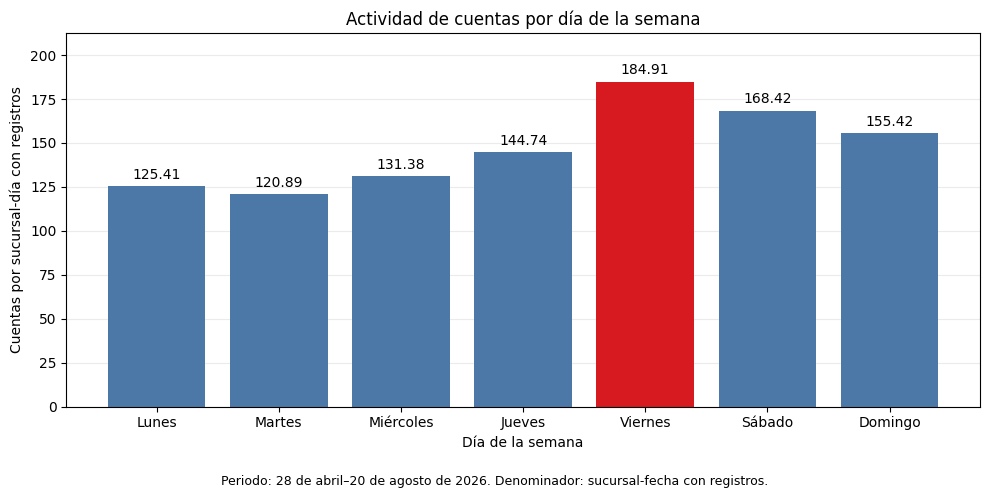

In [0]:
import matplotlib.pyplot as plt

# Llevar a pandas únicamente el resumen de siete filas
semanal_pdf = resumen_semanal.orderBy("dia_semana_num").toPandas()

fig, ax = plt.subplots(figsize=(10, 5))

colores = [
    "#D71920" if dia == "Viernes" else "#4C78A8"
    for dia in semanal_pdf["dia_semana"]
]

barras = ax.bar(
    semanal_pdf["dia_semana"],
    semanal_pdf["cuentas_por_sucursal_dia"],
    color=colores
)

ax.bar_label(barras, fmt="%.2f", padding=3)

ax.set_title("Actividad de cuentas por día de la semana")
ax.set_xlabel("Día de la semana")
ax.set_ylabel("Cuentas por sucursal-día con registros")
ax.set_ylim(
    0,
    semanal_pdf["cuentas_por_sucursal_dia"].max() * 1.15
)

ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

fig.text(
    0.5, 0.02,
    "Periodo: 28 de abril–20 de agosto de 2026. "
    "Denominador: sucursal-fecha con registros.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

In [0]:
# Identificar descuentos a nivel cuenta o artículo
base_semanal = (
    analysis_master
    .withColumn(
        "dia_semana_num",
        F.pmod(
            F.dayofweek("BusinessDate") + F.lit(5),
            F.lit(7)
        ) + F.lit(1)
    )
    .withColumn(
        "tiene_descuento",
        (F.coalesce(F.col("discount_count"), F.lit(0)) > 0)
        |
        F.coalesce(
            F.expr(
                "exists(ItemsSold, item -> size(item.Discounts) > 0)"
            ),
            F.lit(False)
        )
    )
    .withColumn(
        "tiene_anulacion",
        F.coalesce(F.col("void_count"), F.lit(0)) > 0
    )
)

# Contar cuentas y calcular porcentajes
riesgo_semanal = (
    base_semanal
    .groupBy("dia_semana_num")
    .agg(
        F.count("*").alias("total_cuentas"),

        F.sum(
            F.col("tiene_descuento").cast("long")
        ).alias("cuentas_con_descuento"),

        F.sum(
            F.col("tiene_anulacion").cast("long")
        ).alias("cuentas_con_anulacion")
    )
    .withColumn(
        "pct_cuentas_con_descuento",
        F.round(
            100.0 * F.col("cuentas_con_descuento")
            / F.col("total_cuentas"),
            2
        )
    )
    .withColumn(
        "pct_cuentas_con_anulacion",
        F.round(
            100.0 * F.col("cuentas_con_anulacion")
            / F.col("total_cuentas"),
            2
        )
    )
    .withColumn(
        "dia_semana",
        F.element_at(nombres_dias, F.col("dia_semana_num"))
    )
    .select(
        "dia_semana_num",
        "dia_semana",
        "total_cuentas",
        "cuentas_con_descuento",
        "pct_cuentas_con_descuento",
        "cuentas_con_anulacion",
        "pct_cuentas_con_anulacion"
    )
    .orderBy("dia_semana_num")
)

display(riesgo_semanal)

dia_semana_num,dia_semana,total_cuentas,cuentas_con_descuento,pct_cuentas_con_descuento,cuentas_con_anulacion,pct_cuentas_con_anulacion
1,Lunes,254714,34969,13.73,6386,2.51
2,Martes,260517,34217,13.13,6357,2.44
3,Miércoles,283003,35888,12.68,6761,2.39
4,Jueves,312056,38842,12.45,7747,2.48
5,Viernes,375176,45348,12.09,10237,2.73
6,Sábado,341722,40652,11.9,9160,2.68
7,Domingo,315658,38674,12.25,8472,2.68


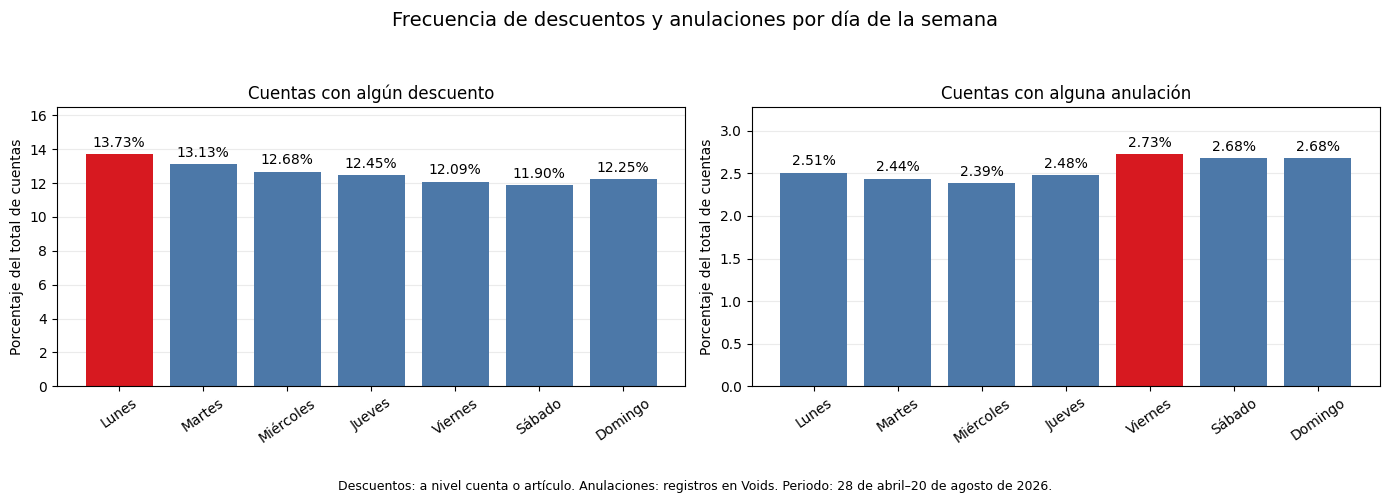

In [0]:
import matplotlib.pyplot as plt

riesgo_pdf = (
    riesgo_semanal
    .orderBy("dia_semana_num")
    .toPandas()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

indicadores = [
    (
        "pct_cuentas_con_descuento",
        "Cuentas con algún descuento",
        "Lunes"
    ),
    (
        "pct_cuentas_con_anulacion",
        "Cuentas con alguna anulación",
        "Viernes"
    )
]

for ax, (columna, titulo, dia_destacado) in zip(axes, indicadores):
    colores = [
        "#D71920" if dia == dia_destacado else "#4C78A8"
        for dia in riesgo_pdf["dia_semana"]
    ]

    barras = ax.bar(
        riesgo_pdf["dia_semana"],
        riesgo_pdf[columna],
        color=colores
    )

    ax.bar_label(barras, fmt="%.2f%%", padding=3)
    ax.set_title(titulo)
    ax.set_ylabel("Porcentaje del total de cuentas")
    ax.set_ylim(0, riesgo_pdf[columna].max() * 1.2)
    ax.tick_params(axis="x", rotation=35)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

fig.suptitle(
    "Frecuencia de descuentos y anulaciones por día de la semana",
    fontsize=14
)

fig.text(
    0.5, 0.02,
    "Descuentos: a nivel cuenta o artículo. "
    "Anulaciones: registros en Voids. "
    "Periodo: 28 de abril–20 de agosto de 2026.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.08, 1, 0.93])
plt.show()

In [0]:
resumen_dia_canal = (
    base_semanal
    .groupBy("dia_semana_num", "RevenueCenterName")
    .agg(
        F.count("*").alias("total_cuentas"),

        F.sum(
            F.col("tiene_descuento").cast("long")
        ).alias("cuentas_con_descuento"),

        F.sum(
            F.col("tiene_anulacion").cast("long")
        ).alias("cuentas_con_anulacion")
    )
    .withColumn(
        "pct_descuento",
        F.round(
            100.0 * F.col("cuentas_con_descuento")
            / F.col("total_cuentas"),
            2
        )
    )
    .withColumn(
        "pct_anulacion",
        F.round(
            100.0 * F.col("cuentas_con_anulacion")
            / F.col("total_cuentas"),
            2
        )
    )
    .withColumn(
        "dia_semana",
        F.element_at(nombres_dias, F.col("dia_semana_num"))
    )
    .select(
        "dia_semana_num",
        "dia_semana",
        "RevenueCenterName",
        "total_cuentas",
        "cuentas_con_descuento",
        "pct_descuento",
        "cuentas_con_anulacion",
        "pct_anulacion"
    )
    .orderBy("RevenueCenterName", "dia_semana_num")
)

display(resumen_dia_canal)

dia_semana_num,dia_semana,RevenueCenterName,total_cuentas,cuentas_con_descuento,pct_descuento,cuentas_con_anulacion,pct_anulacion
6,Sábado,BITESQUAD,1,0,0.0,0,0.0
1,Lunes,Catering,90,14,15.56,1,1.11
2,Martes,Catering,154,21,13.64,4,2.6
3,Miércoles,Catering,134,11,8.21,5,3.73
4,Jueves,Catering,135,15,11.11,1,0.74
5,Viernes,Catering,59,12,20.34,1,1.69
6,Sábado,Catering,39,18,46.15,0,0.0
7,Domingo,Catering,33,13,39.39,2,6.06
1,Lunes,DELIVERLOGIC,3,0,0.0,0,0.0
2,Martes,DELIVERLOGIC,5,0,0.0,0,0.0


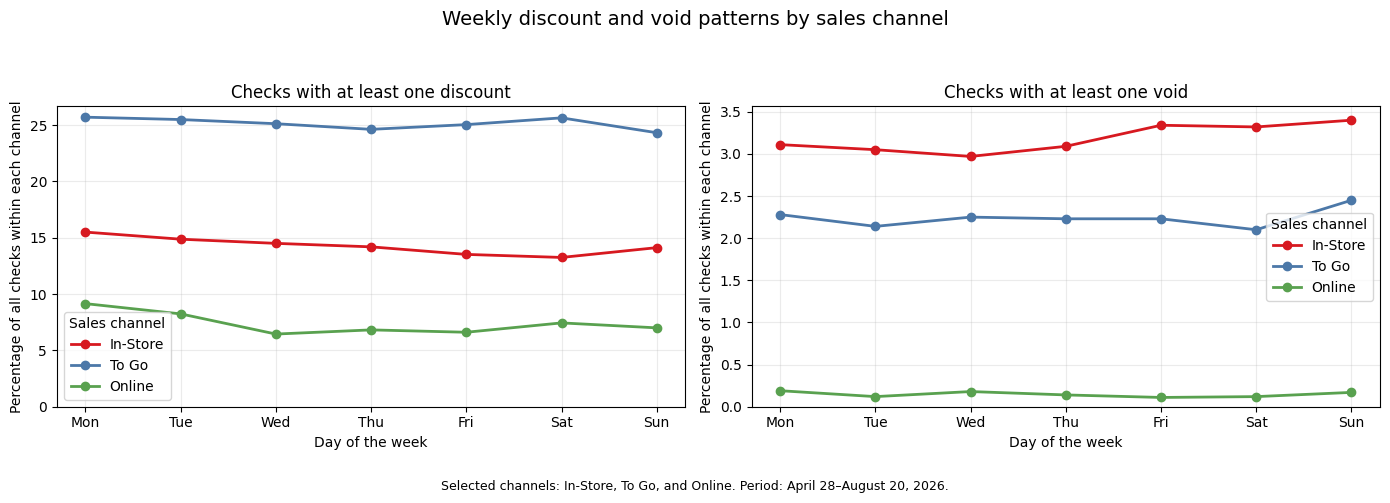

In [0]:
canales_comparacion = ["In-Store", "To Go", "Online"]

canal_pdf = (
    resumen_dia_canal
    .filter(F.col("RevenueCenterName").isin(canales_comparacion))
    .orderBy("dia_semana_num")
    .toPandas()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colores = {
    "In-Store": "#D71920",
    "To Go": "#4C78A8",
    "Online": "#59A14F"
}

indicadores = [
    ("pct_descuento", "Checks with at least one discount"),
    ("pct_anulacion", "Checks with at least one void")
]

for ax, (columna, titulo) in zip(axes, indicadores):
    for canal in canales_comparacion:
        datos = (
            canal_pdf[canal_pdf["RevenueCenterName"] == canal]
            .sort_values("dia_semana_num")
        )

        ax.plot(
            datos["dia_semana_num"],
            datos[columna],
            marker="o",
            linewidth=2,
            color=colores[canal],
            label=canal
        )

    ax.set_xticks(range(1, 8))
    ax.set_xticklabels(
        ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
    )
    ax.set_title(titulo)
    ax.set_xlabel("Day of the week")
    ax.set_ylabel("Percentage of all checks within each channel")
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.25)
    ax.legend(title="Sales channel")

fig.suptitle(
    "Weekly discount and void patterns by sales channel",
    fontsize=14
)

fig.text(
    0.5, 0.02,
    "Selected channels: In-Store, To Go, and Online. "
    "Period: April 28–August 20, 2026.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.07, 1, 0.93])
plt.show()

In [0]:
# Zona horaria utilizada por esta sesión
display(
    spark.sql("""
        SELECT current_timezone() AS zona_horaria_sesion
    """)
)

# Zonas horarias registradas en la tabla
resumen_zonas = (
    analysis_master
    .groupBy("TimeZoneName")
    .agg(
        F.count("*").alias("total_cuentas"),
        F.countDistinct("LocationId").alias("sucursales")
    )
    .orderBy(F.desc("total_cuentas"))
)

display(resumen_zonas)

zona_horaria_sesion
Etc/UTC


TimeZoneName,total_cuentas,sucursales
America/Chicago,1815501,108
America/Phoenix,314279,18
America/New_York,13066,1


In [0]:
# Calcular duración sin modificar las columnas originales
base_duracion = analysis_master.withColumn(
    "duracion_minutos",
    (
        F.col("CloseTime").cast("long")
        - F.col("OpenTime").cast("long")
    ) / 60.0
)

# Resumir la distribución de duraciones
resumen_duracion = base_duracion.agg(
    F.count("*").alias("total_cuentas"),

    F.sum(
        F.when(F.col("duracion_minutos") == 0, 1).otherwise(0)
    ).alias("cuentas_duracion_cero"),

    F.round(
        F.avg("duracion_minutos"), 2
    ).alias("duracion_promedio_min"),

    F.expr(
        "percentile_approx(duracion_minutos, 0.5, 10000)"
    ).alias("mediana_min"),

    F.expr(
        "percentile_approx(duracion_minutos, 0.95, 10000)"
    ).alias("percentil_95_min"),

    F.expr(
        "percentile_approx(duracion_minutos, 0.99, 10000)"
    ).alias("percentil_99_min"),

    F.max("duracion_minutos").alias("duracion_maxima_min")
)

display(resumen_duracion)

total_cuentas,cuentas_duracion_cero,duracion_promedio_min,mediana_min,percentil_95_min,percentil_99_min,duracion_maxima_min
2142846,52503,54.15,46.0,131.0,287.0,1129.0


In [0]:
duracion_por_canal = (
    base_duracion
    .groupBy("RevenueCenterName")
    .agg(
        F.count("*").alias("total_cuentas"),

        F.sum(
            F.when(F.col("duracion_minutos") == 0, 1).otherwise(0)
        ).alias("cuentas_duracion_cero"),

        F.round(
            F.avg("duracion_minutos"), 2
        ).alias("promedio_min"),

        F.expr(
            "percentile_approx(duracion_minutos, 0.5, 10000)"
        ).alias("mediana_min"),

        F.expr(
            "percentile_approx(duracion_minutos, 0.95, 10000)"
        ).alias("p95_min"),

        F.expr(
            "percentile_approx(duracion_minutos, 0.99, 10000)"
        ).alias("p99_min"),

        F.max("duracion_minutos").alias("maximo_min")
    )
    .withColumn(
        "pct_duracion_cero",
        F.round(
            100.0 * F.col("cuentas_duracion_cero")
            / F.col("total_cuentas"),
            2
        )
    )
    .select(
        "RevenueCenterName",
        "total_cuentas",
        "cuentas_duracion_cero",
        "pct_duracion_cero",
        "promedio_min",
        "mediana_min",
        "p95_min",
        "p99_min",
        "maximo_min"
    )
    .orderBy(F.desc("total_cuentas"))
)

display(duracion_por_canal)

RevenueCenterName,total_cuentas,cuentas_duracion_cero,pct_duracion_cero,promedio_min,mediana_min,p95_min,p99_min,maximo_min
In-Store,1649922,21517,1.3,60.83,51.0,131.0,285.0,1129.0
Door Dash,197995,11847,5.98,27.3,13.0,108.0,242.0,1048.0
Online,138305,5553,4.02,31.8,17.0,123.0,277.0,996.0
To Go,95357,9099,9.54,38.88,20.0,183.0,373.0,853.0
Uber Eats,47914,2293,4.79,35.11,16.0,144.0,280.0,799.0
GRUBHUB,7020,305,4.34,39.73,17.0,179.0,296.0,835.0
Olo - Visa,2535,1080,42.6,9.66,1.0,45.0,185.0,613.0
POSTMATES,1232,55,4.46,37.25,18.0,148.0,304.0,523.0
Olo - Mastercard,1059,494,46.65,7.17,1.0,37.0,162.0,573.0
Catering,644,136,21.12,75.95,9.0,348.0,739.0,1045.0


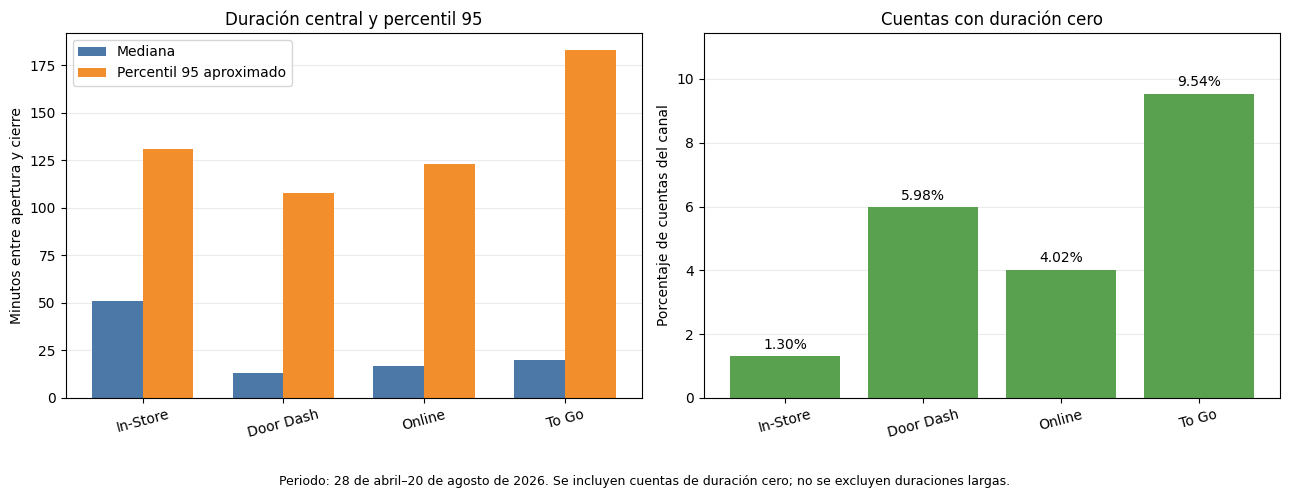

In [0]:
import matplotlib.pyplot as plt

canales_duracion = ["In-Store", "Door Dash", "Online", "To Go"]

duracion_pdf = (
    duracion_por_canal
    .filter(F.col("RevenueCenterName").isin(canales_duracion))
    .toPandas()
    .set_index("RevenueCenterName")
    .loc[canales_duracion]
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Mediana y percentil 95
x = list(range(len(duracion_pdf)))
ancho = 0.36

axes[0].bar(
    [i - ancho / 2 for i in x],
    duracion_pdf["mediana_min"],
    width=ancho,
    label="Mediana",
    color="#4C78A8"
)

axes[0].bar(
    [i + ancho / 2 for i in x],
    duracion_pdf["p95_min"],
    width=ancho,
    label="Percentil 95 aproximado",
    color="#F28E2B"
)

axes[0].set_xticks(x)
axes[0].set_xticklabels(duracion_pdf["RevenueCenterName"])
axes[0].set_title("Duración central y percentil 95")
axes[0].set_ylabel("Minutos entre apertura y cierre")
axes[0].legend()

# Porcentaje de cuentas de duración cero
barras = axes[1].bar(
    duracion_pdf["RevenueCenterName"],
    duracion_pdf["pct_duracion_cero"],
    color="#59A14F"
)

axes[1].bar_label(barras, fmt="%.2f%%", padding=3)
axes[1].set_title("Cuentas con duración cero")
axes[1].set_ylabel("Porcentaje de cuentas del canal")
axes[1].set_ylim(
    0,
    duracion_pdf["pct_duracion_cero"].max() * 1.2
)

for ax in axes:
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    ax.tick_params(axis="x", rotation=15)

fig.text(
    0.5, 0.02,
    "Periodo: 28 de abril–20 de agosto de 2026. "
    "Se incluyen cuentas de duración cero; no se excluyen duraciones largas.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.show()

In [0]:
# Recuperar el percentil 95 calculado para In-Store
umbral_instore = (
    duracion_por_canal
    .filter(F.col("RevenueCenterName") == "In-Store")
    .select("p95_min")
    .first()["p95_min"]
)

# Utilizar las banderas de descuentos y anulaciones ya calculadas
comparacion_duracion = (
    base_semanal
    .filter(F.col("RevenueCenterName") == "In-Store")
    .withColumn(
        "duracion_minutos",
        (
            F.col("CloseTime").cast("long")
            - F.col("OpenTime").cast("long")
        ) / 60.0
    )
    .withColumn(
        "grupo_duracion",
        F.when(
            F.col("duracion_minutos") > umbral_instore,
            "Por encima del P95"
        ).otherwise("Hasta el P95")
    )
    .groupBy("grupo_duracion")
    .agg(
        F.count("*").alias("total_cuentas"),

        F.sum(
            F.col("tiene_descuento").cast("long")
        ).alias("cuentas_con_descuento"),

        F.sum(
            F.col("tiene_anulacion").cast("long")
        ).alias("cuentas_con_anulacion"),

        F.round(
            F.avg("duracion_minutos"), 2
        ).alias("duracion_promedio_min")
    )
    .withColumn(
        "pct_descuento",
        F.round(
            100.0 * F.col("cuentas_con_descuento")
            / F.col("total_cuentas"),
            2
        )
    )
    .withColumn(
        "pct_anulacion",
        F.round(
            100.0 * F.col("cuentas_con_anulacion")
            / F.col("total_cuentas"),
            2
        )
    )
    .withColumn("umbral_minutos", F.lit(umbral_instore))
    .orderBy("grupo_duracion")
)

display(comparacion_duracion)

grupo_duracion,total_cuentas,cuentas_con_descuento,cuentas_con_anulacion,duracion_promedio_min,pct_descuento,pct_anulacion,umbral_minutos
Hasta el P95,1567747,203362,46607,52.39,12.97,2.97,131.0
Por encima del P95,82175,30704,6131,221.89,37.36,7.46,131.0


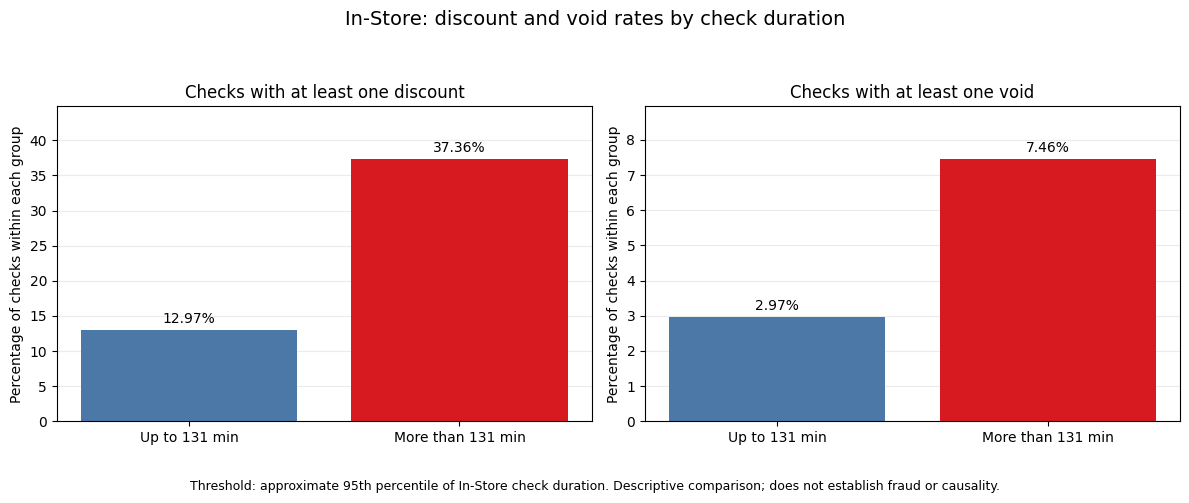

In [0]:
import matplotlib.pyplot as plt

orden_grupos = ["Hasta el P95", "Por encima del P95"]

comparacion_pdf = (
    comparacion_duracion
    .toPandas()
    .set_index("grupo_duracion")
    .loc[orden_grupos]
    .reset_index()
)

etiquetas = [
    f"Up to {umbral_instore:g} min",
    f"More than {umbral_instore:g} min"
]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

indicadores = [
    ("pct_descuento", "Checks with at least one discount"),
    ("pct_anulacion", "Checks with at least one void")
]

for ax, (columna, titulo) in zip(axes, indicadores):
    barras = ax.bar(
        etiquetas,
        comparacion_pdf[columna],
        color=["#4C78A8", "#D71920"]
    )

    ax.bar_label(barras, fmt="%.2f%%", padding=3)
    ax.set_title(titulo)
    ax.set_ylabel("Percentage of checks within each group")
    ax.set_ylim(0, comparacion_pdf[columna].max() * 1.2)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

fig.suptitle(
    "In-Store: discount and void rates by check duration",
    fontsize=14
)

fig.text(
    0.5, 0.02,
    "Threshold: approximate 95th percentile of In-Store check duration. "
    "Descriptive comparison; does not establish fraud or causality.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.08, 1, 0.93])
plt.show()

In [0]:
base_tamano = (
    base_semanal
    .filter(F.col("RevenueCenterName") == "In-Store")
    .withColumn(
        "duracion_minutos",
        (
            F.col("CloseTime").cast("long")
            - F.col("OpenTime").cast("long")
        ) / 60.0
    )
    .withColumn(
        "grupo_duracion",
        F.when(
            F.col("duracion_minutos") > umbral_instore,
            "Por encima del P95"
        ).otherwise("Hasta el P95")
    )
    .withColumn(
        "grupo_articulos",
        F.when(
            F.col("item_event_count").isNull(), "Sin dato"
        )
        .when(F.col("item_event_count") < 0, "Valor negativo")
        .when(F.col("item_event_count") == 0, "0 registros")
        .when(F.col("item_event_count") <= 5, "1-5 registros")
        .when(F.col("item_event_count") <= 10, "6-10 registros")
        .otherwise("11+ registros")
    )
)

comparacion_por_tamano = (
    base_tamano
    .groupBy("grupo_articulos", "grupo_duracion")
    .agg(
        F.count("*").alias("total_cuentas"),

        F.sum(
            F.col("tiene_descuento").cast("long")
        ).alias("cuentas_con_descuento"),

        F.sum(
            F.col("tiene_anulacion").cast("long")
        ).alias("cuentas_con_anulacion")
    )
    .withColumn(
        "pct_descuento",
        F.round(
            100.0 * F.col("cuentas_con_descuento")
            / F.col("total_cuentas"),
            2
        )
    )
    .withColumn(
        "pct_anulacion",
        F.round(
            100.0 * F.col("cuentas_con_anulacion")
            / F.col("total_cuentas"),
            2
        )
    )
    .orderBy("grupo_articulos", "grupo_duracion")
)

display(comparacion_por_tamano)

grupo_articulos,grupo_duracion,total_cuentas,cuentas_con_descuento,cuentas_con_anulacion,pct_descuento,pct_anulacion
0 registros,Hasta el P95,7757,0,4964,0.0,63.99
0 registros,Por encima del P95,2420,0,2393,0.0,98.88
1-5 registros,Hasta el P95,325195,40898,6166,12.58,1.9
1-5 registros,Por encima del P95,26913,13724,1669,50.99,6.2
11+ registros,Hasta el P95,780950,109806,26826,14.06,3.44
11+ registros,Por encima del P95,29841,8140,1451,27.28,4.86
6-10 registros,Hasta el P95,453845,52658,8651,11.6,1.91
6-10 registros,Por encima del P95,23001,8840,618,38.43,2.69


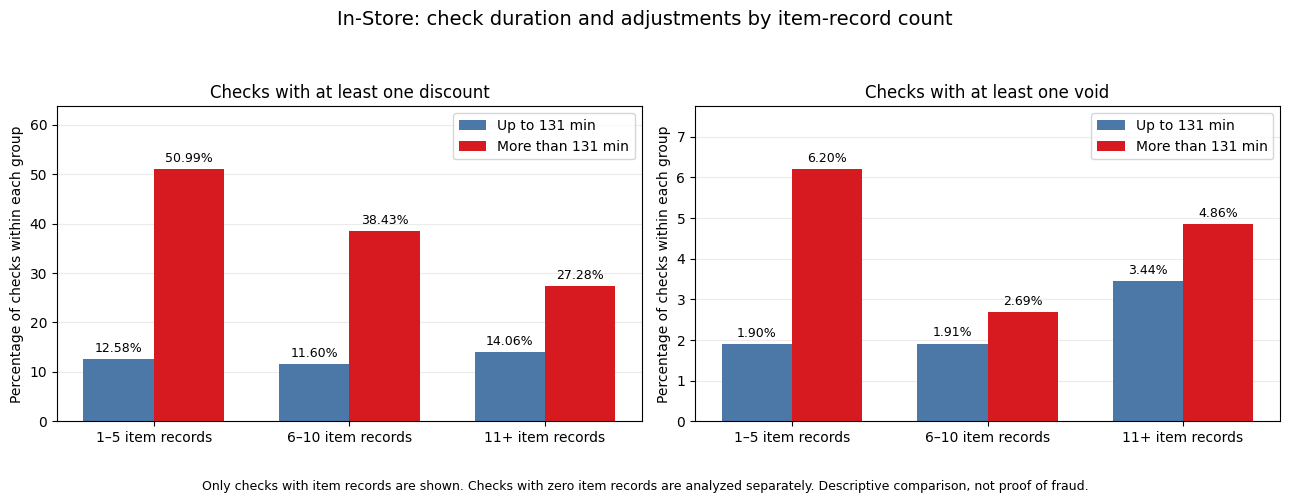

In [0]:
import matplotlib.pyplot as plt

orden_articulos = [
    "1-5 registros",
    "6-10 registros",
    "11+ registros"
]

etiquetas_articulos = [
    "1–5 item records",
    "6–10 item records",
    "11+ item records"
]

orden_duracion = [
    "Hasta el P95",
    "Por encima del P95"
]

tamano_pdf = (
    comparacion_por_tamano
    .filter(F.col("grupo_articulos").isin(orden_articulos))
    .toPandas()
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

indicadores = [
    ("pct_descuento", "Checks with at least one discount"),
    ("pct_anulacion", "Checks with at least one void")
]

x = list(range(len(orden_articulos)))
ancho = 0.36

for ax, (columna, titulo) in zip(axes, indicadores):
    tabla = (
        tamano_pdf
        .pivot(
            index="grupo_articulos",
            columns="grupo_duracion",
            values=columna
        )
        .reindex(
            index=orden_articulos,
            columns=orden_duracion
        )
    )

    for posicion, grupo in enumerate(orden_duracion):
        desplazamiento = -ancho / 2 if posicion == 0 else ancho / 2

        barras = ax.bar(
            [i + desplazamiento for i in x],
            tabla[grupo],
            width=ancho,
            color=["#4C78A8", "#D71920"][posicion],
            label=(
                f"Up to {umbral_instore:g} min"
                if posicion == 0
                else f"More than {umbral_instore:g} min"
            )
        )

        ax.bar_label(
            barras,
            fmt="%.2f%%",
            padding=3,
            fontsize=9
        )

    ax.set_xticks(x)
    ax.set_xticklabels(etiquetas_articulos)
    ax.set_title(titulo)
    ax.set_ylabel("Percentage of checks within each group")
    ax.set_ylim(0, tabla.max().max() * 1.25)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    ax.legend()

fig.suptitle(
    "In-Store: check duration and adjustments by item-record count",
    fontsize=14
)

fig.text(
    0.5, 0.02,
    "Only checks with item records are shown. "
    "Checks with zero item records are analyzed separately. "
    "Descriptive comparison, not proof of fraud.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.08, 1, 0.93])
plt.show()

### Interpretación de horarios: pendiente de validación

OpenTime y CloseTime fueron convertidos de string a timestamp
sin una conversión explícita de zona horaria, según el responsable
de la preparación de datos.

La sesión actual de análisis utiliza Etc/UTC. Aún falta confirmar
si las horas originales representan horarios locales o UTC y cuál
era la zona de la sesión durante la conversión.

Por este motivo, todavía no se presentan conclusiones por hora
local del restaurante. Los análisis semanales utilizan BusinessDate.

In [0]:
serie_diaria_instore = (
    base_semanal
    .filter(F.col("RevenueCenterName") == "In-Store")
    .groupBy("BusinessDate")
    .agg(
        F.count("*").alias("total_cuentas"),

        F.countDistinct("LocationId").alias("sucursales_con_datos"),

        F.sum(
            F.col("tiene_descuento").cast("long")
        ).alias("cuentas_con_descuento"),

        F.sum(
            F.col("tiene_anulacion").cast("long")
        ).alias("cuentas_con_anulacion")
    )
    .withColumn(
        "pct_descuento",
        F.round(
            100.0 * F.col("cuentas_con_descuento")
            / F.col("total_cuentas"),
            2
        )
    )
    .withColumn(
        "pct_anulacion",
        F.round(
            100.0 * F.col("cuentas_con_anulacion")
            / F.col("total_cuentas"),
            2
        )
    )
    .orderBy("BusinessDate")
)

display(serie_diaria_instore)

BusinessDate,total_cuentas,sucursales_con_datos,cuentas_con_descuento,cuentas_con_anulacion,pct_descuento,pct_anulacion
2026-04-28,11728,126,1669,355,14.23,3.03
2026-04-29,12407,126,1797,343,14.48,2.76
2026-04-30,13895,126,2030,390,14.61,2.81
2026-05-01,19140,127,2563,617,13.39,3.22
2026-05-02,18604,127,2494,595,13.41,3.2
2026-05-03,14407,127,2026,456,14.06,3.17
2026-05-04,11373,127,1884,303,16.57,2.66
2026-05-05,11699,127,1725,329,14.74,2.81
2026-05-06,11982,127,1883,344,15.72,2.87
2026-05-07,13056,127,1947,386,14.91,2.96


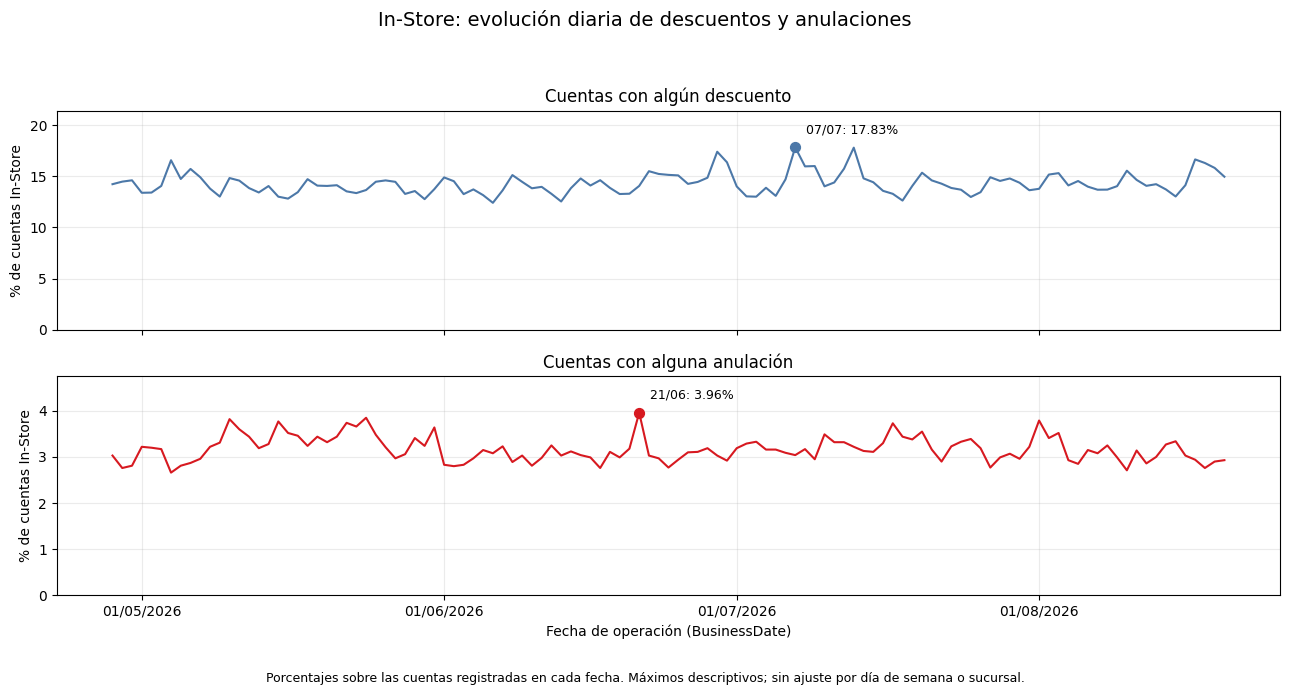

In [0]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

diaria_pdf = (
    serie_diaria_instore
    .orderBy("BusinessDate")
    .toPandas()
)

diaria_pdf["BusinessDate"] = pd.to_datetime(
    diaria_pdf["BusinessDate"]
)

fig, axes = plt.subplots(
    2, 1,
    figsize=(13, 7),
    sharex=True
)

indicadores = [
    (
        "pct_descuento",
        "Cuentas con algún descuento",
        "#4C78A8"
    ),
    (
        "pct_anulacion",
        "Cuentas con alguna anulación",
        "#D71920"
    )
]

for ax, (columna, titulo, color) in zip(axes, indicadores):
    ax.plot(
        diaria_pdf["BusinessDate"],
        diaria_pdf[columna],
        color=color,
        linewidth=1.5
    )

    fila_max = diaria_pdf.loc[diaria_pdf[columna].idxmax()]

    ax.scatter(
        fila_max["BusinessDate"],
        fila_max[columna],
        color=color,
        s=50,
        zorder=3
    )

    etiqueta = (
        f'{fila_max["BusinessDate"]:%d/%m}: '
        f'{fila_max[columna]:.2f}%'
    )

    ax.annotate(
        etiqueta,
        xy=(fila_max["BusinessDate"], fila_max[columna]),
        xytext=(8, 10),
        textcoords="offset points",
        fontsize=9
    )

    ax.set_title(titulo)
    ax.set_ylabel("% de cuentas In-Store")
    ax.set_ylim(0, diaria_pdf[columna].max() * 1.2)
    ax.grid(alpha=0.25)

axes[1].xaxis.set_major_locator(
    mdates.MonthLocator()
)
axes[1].xaxis.set_major_formatter(
    mdates.DateFormatter("%d/%m/%Y")
)
axes[1].set_xlabel("Fecha de operación (BusinessDate)")

fig.suptitle(
    "In-Store: evolución diaria de descuentos y anulaciones",
    fontsize=14
)

fig.text(
    0.5, 0.02,
    "Porcentajes sobre las cuentas registradas en cada fecha. "
    "Máximos descriptivos; sin ajuste por día de semana o sucursal.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.06, 1, 0.94])
plt.show()